# 02. Khám phá dữ liệu giá (EDA)

Bức tranh chung về lợi suất, rủi ro và thanh khoản của VN100 giai đoạn **01/2021 – 09/2026**, chuẩn bị cho Q1 (ngành × rủi ro), Q3 (tương quan) và Q5 (VN30 so với phần còn lại).

- Giá là **giá điều chỉnh** (cổ tức, chia tách). Lãi suất phi rủi ro **3%/năm** (xem README).
- Quy tắc lọc theo `01_data_quality`: chỉ số năm bỏ mã–năm có < 80% số phiên; so sánh **toàn kỳ** chỉ dùng mã có lịch sử từ 01/2021.
- Hàm tính chỉ số: `src/metrics.py` (đã có kiểm tra trên dữ liệu giả và đối chiếu tay).

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mtick, seaborn as sns
from scipy import stats
from db import query
import metrics as m
from config import RISK_FREE_RATE, ROOT

sns.set_theme(style="whitegrid")
pct = mtick.PercentFormatter(1)
SHOT = ROOT / "dashboard" / "screenshots"
REGIME_COLOR = {"Tăng": "#2ca02c", "Giảm": "#d62728", "Đi ngang": "#bdbdbd"}

stocks = query("SELECT ticker, industry_l1, industry_l2, is_vn30, fs_template, first_trade_date FROM dim_stock")
px = query("SELECT ticker, date, close, volume, value_mil_vnd FROM fact_price ORDER BY ticker, date")
px["date"] = pd.to_datetime(px.date)
idx = query("SELECT index_code, date, close FROM fact_index_price ORDER BY date")
idx["date"] = pd.to_datetime(idx.date)
vnindex = idx[idx.index_code == "VNINDEX"].set_index("date").close
vn30 = idx[idx.index_code == "VN30"].set_index("date").close
close = px.pivot(index="date", columns="ticker", values="close")
rets = close.pct_change(fill_method=None)

# Mã có đủ lịch sử toàn kỳ (giao dịch từ tháng 01/2021) dùng cho so sánh toàn kỳ
full = stocks[pd.to_datetime(stocks.first_trade_date) <= "2021-01-31"].ticker
r_idx = m.daily_returns(vnindex)
whole = pd.DataFrame([{
    "ticker": t,
    "ann_return": m.annualized_return(close[t].dropna()),
    "volatility": m.annualized_volatility(rets[t].dropna()),
    "sharpe": m.sharpe(close[t].dropna()),
    "max_drawdown": m.max_drawdown(close[t].dropna())[0],
    "beta": m.beta(rets[t].dropna(), r_idx),
} for t in full]).merge(stocks, on="ticker")
yearly = m.yearly_metrics(px[["ticker", "date", "close"]], vnindex).merge(stocks, on="ticker")
print(f"{len(full)} mã đủ lịch sử toàn kỳ; {len(yearly)} cặp mã–năm sau lọc")
print(f"VN-Index toàn kỳ: lợi suất năm hóa {m.annualized_return(vnindex):.1%}, volatility {m.annualized_volatility(r_idx):.1%}, "
      f"Sharpe {m.sharpe(vnindex):.2f}, max drawdown {m.max_drawdown(vnindex)[0]:.1%}")

91 mã đủ lịch sử toàn kỳ; 570 cặp mã–năm sau lọc
VN-Index toàn kỳ: lợi suất năm hóa 8.4%, volatility 19.9%, Sharpe 0.27, max drawdown -40.3%


## 1. VN-Index qua các giai đoạn thị trường

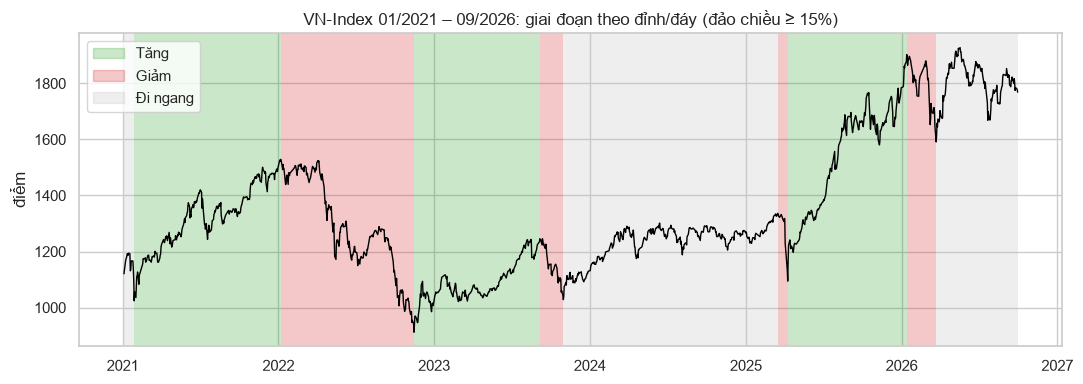

     start        end  sessions change annualized   regime
2021-01-04 2021-01-28        18  -8.6%       -72% Đi ngang
2021-01-28 2022-01-06       234 +49.3%       +54%     Tăng
2022-01-06 2022-11-15       213 -40.3%       -46%     Giảm
2022-11-15 2023-09-06       200 +36.6%       +48%     Tăng
2023-09-06 2023-10-31        39 -17.4%       -71%     Giảm
2023-10-31 2025-03-17       341 +30.0%       +21% Đi ngang
2025-03-17 2025-04-09        16 -18.1%       -96%     Giảm
2025-04-09 2026-01-13       192 +73.9%      +107%     Tăng
2026-01-13 2026-03-23        44 -16.4%       -64%     Giảm
2026-03-23 2026-09-30       131 +11.2%       +23% Đi ngang
regime
Giảm        312
Tăng        626
Đi ngang    490


In [2]:
segs, _ = m.market_regimes(vnindex)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(vnindex.index, vnindex, color="black", lw=1)
for s in segs.itertuples():
    ax.axvspan(s.start, s.end, color=REGIME_COLOR[s.regime], alpha=0.25, lw=0)
for k, c in REGIME_COLOR.items():
    ax.fill_between([], [], color=c, alpha=0.25, label=k)
ax.legend(loc="upper left"); ax.set_ylabel("điểm")
ax.set_title("VN-Index 01/2021 – 09/2026: giai đoạn theo đỉnh/đáy (đảo chiều ≥ 15%)")
plt.tight_layout(); fig.savefig(SHOT / "vnindex_regimes.png", dpi=120); plt.show()
print(segs.assign(change=segs.change.map("{:+.1%}".format), annualized=segs.annualized.map("{:+.0%}".format)).to_string(index=False))
print(segs.groupby("regime").sessions.sum().to_string())

**Nhận xét.** Toàn kỳ VN-Index đạt **+8,4%/năm**, volatility 19,9%, Sharpe 0,27 (rf 3%), sụt sâu nhất **−40,3%** (06/01/2022 → 15/11/2022). Theo đỉnh/đáy có 10 đoạn: **Tăng 626 phiên (44%), Đi ngang 490, Giảm 312**. Đợt giảm nhanh nhất là cú sốc 03–04/2025: **−18,1% chỉ trong 16 phiên**. Ngay sau đó là đợt tăng mạnh nhất giai đoạn: **+73,9%** (04/2025 → 01/2026).

⚠️ Nhãn giai đoạn được xác định **nhìn lại** (biết trước đỉnh/đáy). Chỉ dùng để chia giai đoạn khi phân tích, không dùng làm đặc trưng dự đoán.

## 2. VN30 so với phần còn lại của VN100 (Q5)

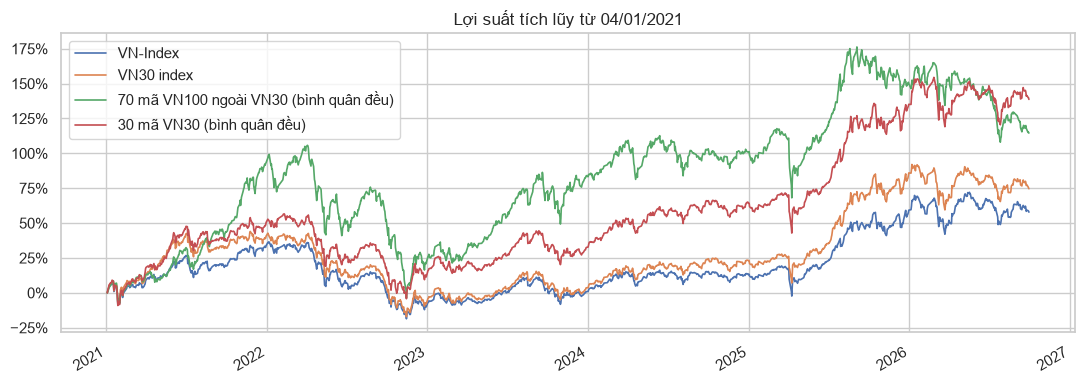

VN-Index                                   +58%
VN30 index                                 +75%
70 mã VN100 ngoài VN30 (bình quân đều)    +115%
30 mã VN30 (bình quân đều)                +139%

Trung vị theo năm (True = VN30):
            ret            vol       
is_vn30   False   True   False  True 
year                                 
2021      73.2%   50.5%  42.7%  35.8%
2022     -42.7%  -28.8%  53.3%  42.1%
2023      40.9%   23.3%  37.9%  26.9%
2024      11.5%    9.4%  29.3%  24.0%
2025      12.4%   28.5%  37.3%  32.8%
2026     -15.5%   -3.9%  35.1%  31.9%


In [3]:
is30 = stocks.set_index("ticker").is_vn30
ew_rest = rets.loc[:, ~is30.reindex(rets.columns).values].mean(axis=1)   # bình quân đều, mã có giá hôm đó
ew_30 = rets.loc[:, is30.reindex(rets.columns).values].mean(axis=1)
cum = pd.DataFrame({
    "VN-Index": vnindex / vnindex.iloc[0] - 1,
    "VN30 index": vn30 / vn30.iloc[0] - 1,
    "70 mã VN100 ngoài VN30 (bình quân đều)": (1 + ew_rest.fillna(0)).cumprod() - 1,
    "30 mã VN30 (bình quân đều)": (1 + ew_30.fillna(0)).cumprod() - 1,
})
ax = cum.plot(figsize=(11, 4), lw=1.2, title="Lợi suất tích lũy từ 04/01/2021")
ax.yaxis.set_major_formatter(pct); ax.set_xlabel("")
plt.tight_layout(); plt.show()
print(cum.iloc[-1].map("{:+.0%}".format).to_string())
g = yearly.groupby(["year", "is_vn30"]).agg(ret=("total_return", "median"), vol=("volatility", "median")).unstack()
print("\nTrung vị theo năm (True = VN30):"); print(g.map("{:.1%}".format).to_string())

**Nhận xét (Q5).**
- **Theo chỉ số:** VN30 index **+75%** so với VN-Index **+58%** cả kỳ.
- **Bình quân đều từng mã:** nhóm VN30 **+139%**, 70 mã còn lại **+115%**. Cả hai đều cao hơn chỉ số vì (1) bình quân đều cho mã nhỏ trọng số ngang mã lớn, và (2) **survivorship bias**: chỉ gồm mã đang nằm trong VN100 hiện tại.
- **Theo năm:** nhóm ngoài VN30 biến động mạnh hơn. Volatility trung vị cao hơn 3–11 điểm %. Nhóm này tăng mạnh hơn trong năm tăng (2021: 73% so với 51%; 2023: 41% so với 23%) và giảm sâu hơn trong năm giảm (2022: −43% so với −29%).
- **Ngoại lệ 2025:** VN30 thắng rõ (28,5% so với 12,4%). Sóng tăng 2025 tập trung vào cổ phiếu vốn hóa lớn.

## 3. Lợi suất ngày của VN-Index có phân phối chuẩn không?

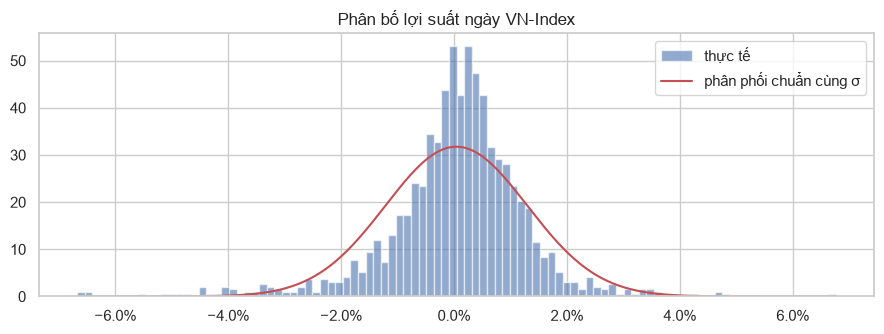

σ ngày = 1.26%; độ nhọn dư (excess kurtosis) = 4.6; độ lệch = -0.82
Phiên vượt ±3σ: 29 thực tế vs 3.9 nếu chuẩn
5 phiên giảm mạnh nhất: {Timestamp('2025-04-03 00:00:00'): '-6.7%', Timestamp('2021-01-28 00:00:00'): '-6.7%', Timestamp('2026-03-09 00:00:00'): '-6.5%', Timestamp('2025-04-08 00:00:00'): '-6.4%', Timestamp('2025-10-20 00:00:00'): '-5.5%'}


In [4]:
z = (r_idx - r_idx.mean()) / r_idx.std()
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(r_idx, bins=100, density=True, alpha=0.6, label="thực tế")
x = np.linspace(r_idx.min(), r_idx.max(), 400)
ax.plot(x, stats.norm.pdf(x, r_idx.mean(), r_idx.std()), "r", label="phân phối chuẩn cùng σ")
ax.xaxis.set_major_formatter(pct); ax.legend(); ax.set_title("Phân bố lợi suất ngày VN-Index")
plt.tight_layout(); plt.show()
n3 = (z.abs() > 3).sum()
print(f"σ ngày = {r_idx.std():.2%}; độ nhọn dư (excess kurtosis) = {stats.kurtosis(r_idx):.1f}; độ lệch = {stats.skew(r_idx):.2f}")
print(f"Phiên vượt ±3σ: {n3} thực tế vs {len(z) * 2 * stats.norm.sf(3):.1f} nếu chuẩn")
print("5 phiên giảm mạnh nhất:", r_idx.nsmallest(5).map("{:.1%}".format).to_dict())

**Nhận xét.** Lợi suất ngày **không theo phân phối chuẩn**: độ nhọn dư 4,6, lệch trái −0,82. Có **29 phiên vượt ±3σ**, trong khi phân phối chuẩn chỉ dự kiến khoảng 4 phiên, tức nhiều gấp 7 lần. Các phiên giảm mạnh nhất từ −5,5% đến −6,7%: 28/01/2021, 03/04/2025, 08/04/2025, 09/03/2026, 20/10/2025.

→ Volatility và Sharpe (dựa trên độ lệch chuẩn) **đánh giá thấp rủi ro cú sốc**. Vì vậy cần xem thêm max drawdown.

## 4. Lợi suất năm theo ngành (Q1)

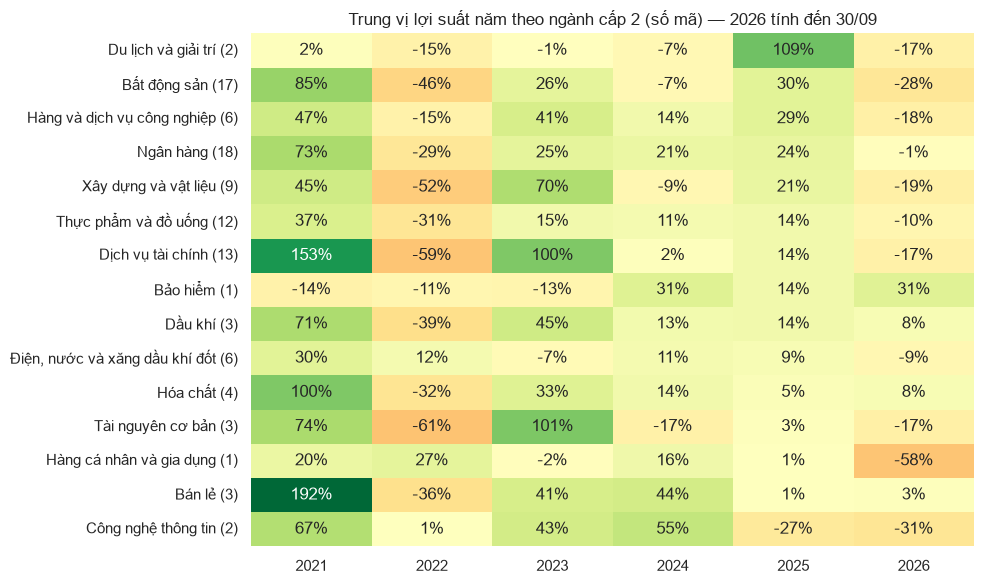

VN-Index theo năm: {2021: '+34%', 2022: '-33%', 2023: '+12%', 2024: '+12%', 2025: '+41%', 2026: '-1%'}
year                             2021  2022   2023  2024   2025  2026
industry_l2                                                          
Du lịch và giải trí               +2%  -15%    -1%   -7%  +109%  -17%
Bất động sản                     +85%  -46%   +26%   -7%   +30%  -28%
Hàng và dịch vụ công nghiệp      +47%  -15%   +41%  +14%   +29%  -18%
Ngân hàng                        +73%  -29%   +25%  +21%   +24%   -1%
Xây dựng và vật liệu             +45%  -52%   +70%   -9%   +21%  -19%
Thực phẩm và đồ uống             +37%  -31%   +15%  +11%   +14%  -10%
Dịch vụ tài chính               +153%  -59%  +100%   +2%   +14%  -17%
Bảo hiểm                         -14%  -11%   -13%  +31%   +14%  +31%
Dầu khí                          +71%  -39%   +45%  +13%   +14%   +8%
Điện, nước và xăng dầu khí đốt   +30%  +12%    -7%  +11%    +9%   -9%
Hóa chất                        +100%  -32%   +33%  +14% 

In [5]:
heat = yearly.pivot_table(index="industry_l2", columns="year", values="total_return", aggfunc="median")
heat["n_ma"] = yearly.groupby("industry_l2").ticker.nunique()
heat = heat.sort_values(2025, ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(heat.drop(columns="n_ma"), annot=True, fmt=".0%", cmap="RdYlGn", center=0, cbar=False, ax=ax,
            yticklabels=[f"{i} ({n})" for i, n in heat.n_ma.items()])
ax.set_title("Trung vị lợi suất năm theo ngành cấp 2 (số mã) — 2026 tính đến 30/09")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); fig.savefig(SHOT / "industry_year_heatmap.png", dpi=120); plt.show()
vn = (vnindex.groupby(vnindex.index.year).last() / vnindex.groupby(vnindex.index.year).last().shift() - 1)
vn.iloc[0] = vnindex[vnindex.index.year == 2021].iloc[-1] / vnindex.iloc[0] - 1
print("VN-Index theo năm:", vn.map("{:+.0%}".format).to_dict())
print(heat.drop(columns="n_ma").map("{:+.0%}".format).to_string())

**Nhận xét (Q1).** Ngành **xoay vòng mạnh**, không ngành nào đứng đầu liên tục.
- **Dịch vụ tài chính (chứng khoán)** biến động lớn nhất: +153% (2021), −59% (2022), +100% (2023).
- **Bán lẻ** dẫn đầu năm 2021 (+192%) và 2024 (+44%). **Công nghệ thông tin** mạnh từ 2021 đến 2024, rồi đảo chiều −27% (2025) và −31% (2026).
- Năm 2022 (VN-Index −33%), chỉ có Điện nước (+12%), Hàng cá nhân (+27%) và CNTT (+1%) dương. Đây là nhóm phòng thủ.

⚠️ Bảo hiểm (BVH), Hàng cá nhân (PNJ), Du lịch (VJC, có thêm VPL từ 2025) chỉ có 1 mã; CNTT có 2 mã (FPT, CMG). Trung vị của các ngành này thực chất là kết quả của 1–2 mã. Khi trả lời Q1 nên gộp ngành cấp 1 hoặc nêu rõ số mã.

## 5. Mã tăng mạnh nhất và yếu nhất (toàn kỳ, lợi suất năm hóa)

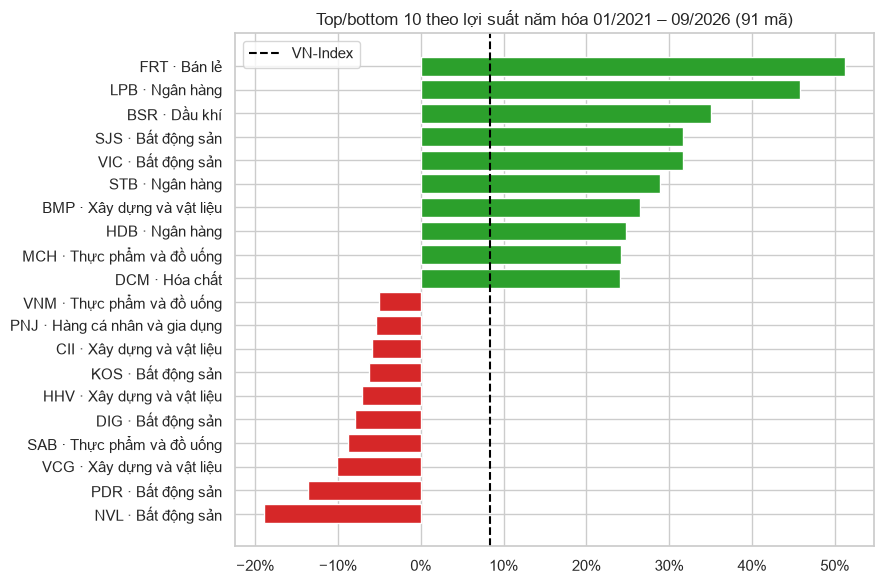

Mã thắng VN-Index: 46/91; trung vị 8.8%; lợi suất âm: 21 mã
ticker              industry_l2  ann_return  volatility  max_drawdown
   NVL             Bất động sản      -0.189       0.429        -0.912
   PDR             Bất động sản      -0.137       0.416        -0.861
   VCG     Xây dựng và vật liệu      -0.101       0.405        -0.758
   SAB     Thực phẩm và đồ uống      -0.088       0.260        -0.521
   DIG             Bất động sản      -0.080       0.539        -0.897
   HHV     Xây dựng và vật liệu      -0.071       0.469        -0.749
   KOS             Bất động sản      -0.062       0.152        -0.598
   CII     Xây dựng và vật liệu      -0.059       0.487        -0.814
   PNJ Hàng cá nhân và gia dụng      -0.054       0.340        -0.686
   VNM     Thực phẩm và đồ uống      -0.051       0.239        -0.458
   DCM                 Hóa chất       0.241       0.432        -0.495
   MCH     Thực phẩm và đồ uống       0.242       0.302        -0.530
   HDB                Ngân hàn

In [6]:
top = pd.concat([whole.nlargest(10, "ann_return"), whole.nsmallest(10, "ann_return")]).sort_values("ann_return")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.ticker + " · " + top.industry_l2, top.ann_return, color=np.where(top.ann_return > 0, "#2ca02c", "#d62728"))
ax.axvline(m.annualized_return(vnindex), color="black", ls="--", label="VN-Index")
ax.xaxis.set_major_formatter(pct); ax.legend(); ax.set_title(f"Top/bottom 10 theo lợi suất năm hóa 01/2021 – 09/2026 ({len(whole)} mã)")
plt.tight_layout(); plt.show()
print(f"Mã thắng VN-Index: {(whole.ann_return > m.annualized_return(vnindex)).sum()}/{len(whole)}; "
      f"trung vị {whole.ann_return.median():.1%}; lợi suất âm: {(whole.ann_return < 0).sum()} mã")
print(top[["ticker", "industry_l2", "ann_return", "volatility", "max_drawdown"]].round(3).to_string(index=False))

**Nhận xét.** Qua gần 6 năm, chỉ **46/91 mã thắng VN-Index**. Trung vị lợi suất năm hóa là 8,8%/năm, ngang VN-Index (8,4%/năm). **21 mã có lợi suất âm.**
- **Nhóm yếu nhất:** 6/10 mã thuộc bất động sản và xây dựng, ví dụ NVL −18,9%/năm (từng sụt −91% từ đỉnh), PDR, DIG, CII. Các mã tiêu dùng lớn VNM, SAB, PNJ cũng âm.
- **Nhóm mạnh nhất:** FRT +51%/năm, LPB +46%/năm, BSR +35%/năm.

## 6. Rủi ro và lợi suất (Q1, Q5)

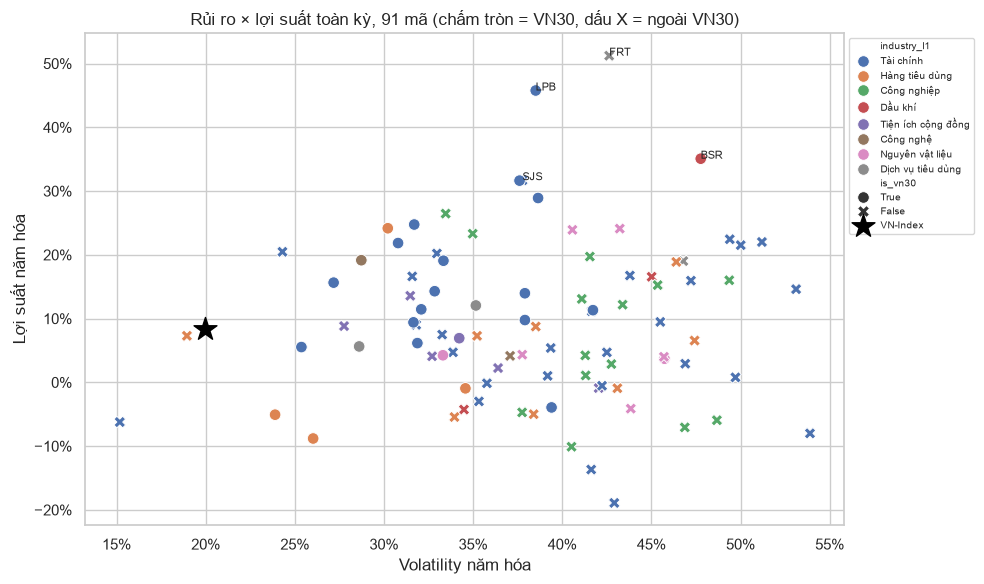

Tương quan hạng volatility – lợi suất: -0.01 (p = 0.917)
         ann_return  volatility  sharpe  max_drawdown   beta
is_vn30                                                     
False         0.069       0.414   0.098        -0.648  1.092
True          0.115       0.333   0.258        -0.555  1.108

Sharpe cao nhất:
ticker  industry_l2  sharpe  ann_return  volatility
   FRT       Bán lẻ    1.13        0.51        0.43
   LPB    Ngân hàng    1.11        0.46        0.39
   VIC Bất động sản    0.76        0.32        0.38
   SJS Bất động sản    0.76        0.32        0.38
   VPI Bất động sản    0.72        0.20        0.24


In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=whole, x="volatility", y="ann_return", hue="industry_l1", style="is_vn30",
                style_order=[True, False], s=70, ax=ax)
ax.scatter(m.annualized_volatility(r_idx), m.annualized_return(vnindex), marker="*", s=300, c="black", label="VN-Index")
for r in whole.nlargest(4, "ann_return").itertuples():
    ax.annotate(r.ticker, (r.volatility, r.ann_return), fontsize=8)
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set_xlabel("Volatility năm hóa"); ax.set_ylabel("Lợi suất năm hóa")
ax.set_title("Rủi ro × lợi suất toàn kỳ, 91 mã (chấm tròn = VN30, dấu X = ngoài VN30)"); ax.legend(fontsize=7, bbox_to_anchor=(1, 1))
plt.tight_layout(); fig.savefig(SHOT / "risk_return_scatter.png", dpi=120); plt.show()
rho = stats.spearmanr(whole.volatility, whole.ann_return)
print(f"Tương quan hạng volatility – lợi suất: {rho.statistic:.2f} (p = {rho.pvalue:.3f})")
print(whole.groupby("is_vn30")[["ann_return", "volatility", "sharpe", "max_drawdown", "beta"]].median().round(3).to_string())
print("\nSharpe cao nhất:"); print(whole.nlargest(5, "sharpe")[["ticker", "industry_l2", "sharpe", "ann_return", "volatility"]].round(2).to_string(index=False))

**Nhận xét.**
- **Rủi ro cao không đi kèm lợi suất cao:** tương quan hạng giữa volatility và lợi suất toàn kỳ là **ρ = −0,01 (p = 0,92)**, gần như bằng 0.
- **VN30 tốt hơn trên mọi thước đo điều chỉnh rủi ro (Q5).** So sánh trung vị VN30 với nhóm còn lại:
  - Lợi suất: 11,5% so với 6,9%.
  - Volatility: 33% so với 41%.
  - Sharpe: 0,26 so với 0,10.
  - Max drawdown: −56% so với −65%.
  - Beta gần như bằng nhau (1,11 so với 1,09), nên khác biệt nằm ở **rủi ro riêng của từng mã**, không phải ở độ nhạy với thị trường.
- Hầu hết các mã đơn lẻ biến động hơn VN-Index (19,9%). Đó là lợi ích của đa dạng hóa trong chỉ số, và là tiền đề cho Q3.

## 7. Mức sụt giảm sâu nhất theo ngành

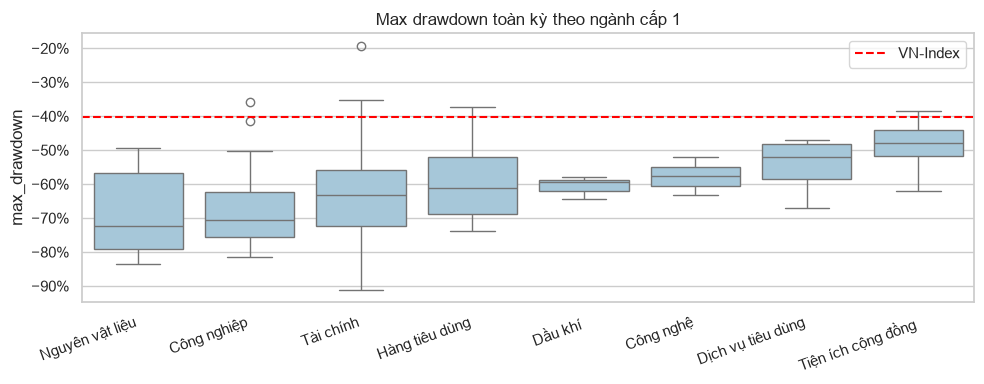

                     n  mdd_median
industry_l1                       
Nguyên vật liệu      7      -0.724
Công nghiệp         14      -0.704
Tài chính           43      -0.632
Hàng tiêu dùng      12      -0.612
Dầu khí              3      -0.595
Công nghệ            2      -0.577
Dịch vụ tiêu dùng    4      -0.521
Tiện ích cộng đồng   6      -0.477
Mã sụt > 50% từ đỉnh: 73/91


In [8]:
order = whole.groupby("industry_l1").max_drawdown.median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=whole, x="industry_l1", y="max_drawdown", order=order, ax=ax, color="#9ecae1")
ax.axhline(m.max_drawdown(vnindex)[0], color="red", ls="--", label="VN-Index")
ax.yaxis.set_major_formatter(pct); ax.set_xlabel(""); ax.legend(); ax.set_title("Max drawdown toàn kỳ theo ngành cấp 1")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()
print(whole.groupby("industry_l1").agg(n=("ticker", "size"), mdd_median=("max_drawdown", "median")).sort_values("mdd_median").round(3).to_string())
print(f"Mã sụt > 50% từ đỉnh: {(whole.max_drawdown < -0.5).sum()}/{len(whole)}")

**Nhận xét.** **73/91 mã từng sụt hơn 50% từ đỉnh**, trong khi VN-Index chỉ sụt −40%. Sụt sâu nhất là Nguyên vật liệu (trung vị −72%) và Công nghiệp (−70%). Nhẹ nhất là Tiện ích cộng đồng (điện, nước: −48%). Nắm giữ một mã đơn lẻ rủi ro hơn nhiều so với nắm chỉ số.

## 8. Thanh khoản tập trung ở đâu?

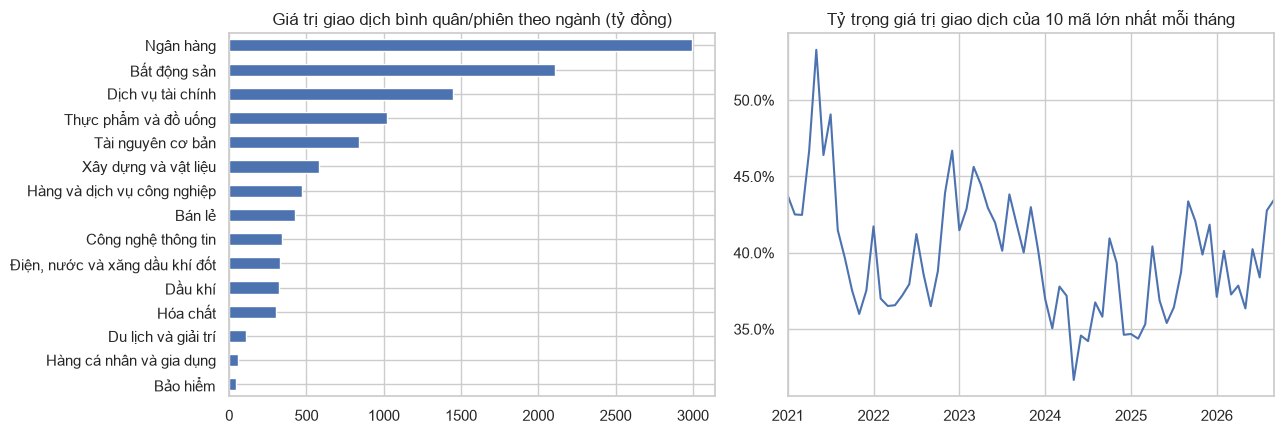

industry_l2
Ngân hàng               26%
Bất động sản            19%
Dịch vụ tài chính       13%
Thực phẩm và đồ uống     9%
Tài nguyên cơ bản        7%
Top 10 mã: trung bình 40% tổng giá trị (thấp nhất 32%, cao nhất 53%)
10 mã thanh khoản nhất toàn kỳ: ['HPG', 'STB', 'SSI', 'SHB', 'FPT', 'MWG', 'VPB', 'VIX', 'TCB', 'VND']


In [9]:
px["industry_l2"] = px.ticker.map(stocks.set_index("ticker").industry_l2)
by_ind = px.groupby("industry_l2").value_mil_vnd.sum() / px.date.nunique() / 1e3   # tỷ đồng/phiên
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
by_ind.sort_values().plot.barh(ax=a1, title="Giá trị giao dịch bình quân/phiên theo ngành (tỷ đồng)")
a1.set_ylabel("")
monthly = px.groupby([px.date.dt.to_period("M"), "ticker"]).value_mil_vnd.sum()
share10 = monthly.groupby(level=0).apply(lambda s: s.nlargest(10).sum() / s.sum())
share10.index = share10.index.to_timestamp()
share10.plot(ax=a2, title="Tỷ trọng giá trị giao dịch của 10 mã lớn nhất mỗi tháng"); a2.yaxis.set_major_formatter(pct); a2.set_xlabel("")
plt.tight_layout(); plt.show()
print((by_ind / by_ind.sum()).sort_values(ascending=False).head(5).map("{:.0%}".format).to_string())
print(f"Top 10 mã: trung bình {share10.mean():.0%} tổng giá trị (thấp nhất {share10.min():.0%}, cao nhất {share10.max():.0%})")
tot = px.groupby("ticker").value_mil_vnd.sum().sort_values(ascending=False)
print("10 mã thanh khoản nhất toàn kỳ:", list(tot.index[:10]))

**Nhận xét.** Thanh khoản **tập trung cao**:
- **Ngân hàng (26%), Bất động sản (19%), Dịch vụ tài chính (13%)** chiếm 58% giá trị giao dịch của VN100.
- **10 mã lớn nhất mỗi tháng chiếm trung bình 40%** tổng giá trị (dao động 32–53%).
- Thanh khoản nhất toàn kỳ: HPG, STB, SSI, SHB, FPT, MWG, VPB, VIX, TCB, VND.

(Giá trị giao dịch = giá điều chỉnh × khối lượng, nên chỉ dùng để so sánh tương đối, xem notebook 01.)

## 9. Rủi ro thị trường thay đổi theo thời gian

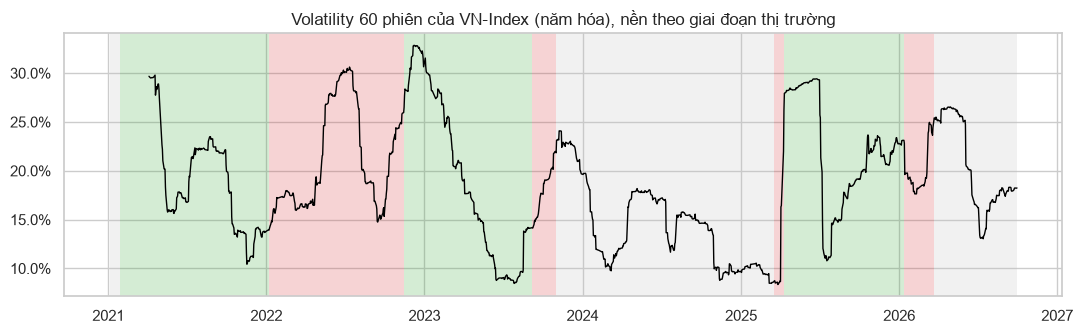

          phien  ret_ngay_tb  vol_nam
Giảm        312      -0.0029   0.2448
Tăng        626       0.0018   0.1996
Đi ngang    490       0.0006   0.1569
Đỉnh volatility 60 phiên: 33% ngày 2022-12-08; thấp nhất 8% ngày 2025-03-27


In [10]:
roll = r_idx.rolling(60).std() * np.sqrt(252)
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(roll.index, roll, color="black", lw=1)
for s in segs.itertuples():
    ax.axvspan(s.start, s.end, color=REGIME_COLOR[s.regime], alpha=0.2, lw=0)
ax.yaxis.set_major_formatter(pct); ax.set_title("Volatility 60 phiên của VN-Index (năm hóa), nền theo giai đoạn thị trường")
plt.tight_layout(); plt.show()
reg = pd.Series(m.market_regimes(vnindex)[1]).reindex(r_idx.index)
print(r_idx.groupby(reg).agg(phien="size", ret_ngay_tb="mean", vol_nam=lambda s: s.std() * np.sqrt(252)).round(4).to_string())
print(f"Đỉnh volatility 60 phiên: {roll.max():.0%} ngày {roll.idxmax().date()}; thấp nhất {roll.min():.0%} ngày {roll.idxmin().date()}")

**Nhận xét.** Volatility 60 phiên cao nhất là **33%** (08/12/2022, ngay sau đáy). Thấp nhất là **8%** (27/03/2025), chỉ một tuần trước cú sốc 04/2025, cho thấy **thị trường yên ắng không có nghĩa là an toàn**. Volatility năm hóa theo giai đoạn: Giảm 24,5%, Tăng 20,0%, Đi ngang 15,7%. Rủi ro tăng khi thị trường giảm.

## 10. Beta theo ngành

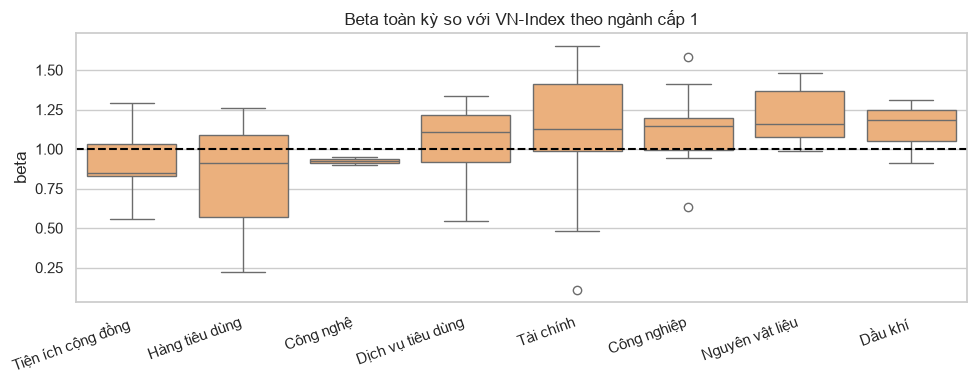

                                size  median
industry_l2                                 
Du lịch và giải trí                1    0.55
Điện, nước và xăng dầu khí đốt     6    0.85
Hàng cá nhân và gia dụng           1    0.87
Công nghệ thông tin                2    0.92
Thực phẩm và đồ uống              11    0.95
Bảo hiểm                           1    0.98
Hàng và dịch vụ công nghiệp        5    0.98
Ngân hàng                         17    1.07
Hóa chất                           4    1.08
Bất động sản                      16    1.11
Xây dựng và vật liệu               9    1.17
Bán lẻ                             3    1.18
Dầu khí                            3    1.19
Tài nguyên cơ bản                  3    1.37
Dịch vụ tài chính                  9    1.56


In [11]:
order = whole.groupby("industry_l1").beta.median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=whole, x="industry_l1", y="beta", order=order, ax=ax, color="#fdae6b")
ax.axhline(1, color="black", ls="--"); ax.set_xlabel(""); ax.set_title("Beta toàn kỳ so với VN-Index theo ngành cấp 1")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()
print(whole.groupby("industry_l2").beta.agg(["size", "median"]).sort_values("median").round(2).to_string())

**Nhận xét.** Dịch vụ tài chính (chủ yếu công ty chứng khoán) có **beta trung vị 1,56**, tức khuếch đại biến động thị trường hơn 1,5 lần, vì doanh thu phụ thuộc trực tiếp vào thanh khoản. Tiếp theo là Tài nguyên cơ bản (1,37). Phòng thủ nhất là Điện nước (0,85) và Thực phẩm và đồ uống (0,95). Ngân hàng sát thị trường (1,07), phù hợp với việc chiếm tỷ trọng lớn trong VN-Index.

## Tóm tắt

**5 quan sát chính (ứng viên cho `insights.md`):**
1. **VN30 vượt trội sau điều chỉnh rủi ro (Q5):** Sharpe trung vị 0,26 so với 0,10, volatility 33% so với 41%, sụt sâu nhất −56% so với −65%. Nhóm ngoài VN30 chỉ thắng trong năm thị trường tăng mạnh (2021, 2023).
2. **Rủi ro cao không được bù bằng lợi suất:** tương quan volatility – lợi suất toàn kỳ ≈ 0 (ρ = −0,01).
3. **Một nửa VN100 thua chỉ số:** 46/91 mã thắng VN-Index, 21 mã lỗ sau gần 6 năm, nhóm yếu nhất tập trung ở bất động sản và xây dựng.
4. **Rủi ro đuôi lớn:** 29 phiên VN-Index vượt ±3σ, gấp 7 lần phân phối chuẩn; 73/91 mã từng sụt hơn 50%.
5. **Ngành xoay vòng, chứng khoán là ngành khuếch đại:** Dịch vụ tài chính có beta 1,56, +153% / −59% / +100% trong 2021–2023; nhóm phòng thủ năm 2022 là điện nước.

**Hạn chế:** survivorship bias (rổ hiện tại), lãi suất phi rủi ro là hằng số 3%, nhãn giai đoạn thị trường được xác định nhìn lại, một số ngành chỉ có 1–2 mã.